# 09 · Mejoras sin datos externos y valor de tener más datos

**Objetivos:**
1. estimar cuánto valdría tener **más tuits etiquetados** (curva de aprendizaje), para decidir si merece la pena pedir autorización para un corpus externo etiquetado;
2. probar mejoras legítimas con los datos que ya hay:
   - P2: entrenar AG sin las filas del artefacto de comillas;
   - especializar los modelos por etiqueta;
   - más semillas en las redes;
   - gemelos del test (P6);
3. decidir con la regla del 07 si un ensamble nuevo (pool v2) sustituye a FINAL_A.

**Referencia: FINAL_A** (`ens07__D__stack-all`) **sin la regla de comillas**: 0.8008 en `folds.csv` y 0.7961 en `folds_seed2`.

**Las comparaciones se hacen sin la regla de comillas,** porque su ganancia es por construcción e igual para cualquier modelo. Al final, la regla se añade a cualquier candidato con `quote_rule=True`, como en el 08.
- **Excepción:** P2 solo tiene sentido con la regla puesta. Si P2 se adopta, desde ese punto todas las comparaciones se hacen **con la regla en los dos lados** (sección 2).

**Reglas de siempre:**
- nada preentrenado;
- todo lo que usa etiquetas, dentro de la CV;
- el texto del test no se usa para entrenar;
- folds compartidos;
- `folds_seed2` solo confirma.

**Ejecución:** es el notebook más costoso desde el 05, ≈2–3 h en CPU la primera vez, sobre todo por las redes con 10 semillas. Cada pieza queda en la caché de `models/09_mejoras/cache/`, así que una ejecución interrumpida continúa donde se quedó. `RECOMPUTE = True` la borra.

## 0. Configuración

In [1]:
import json
import os
import platform
import shutil
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
from IPython.display import display
from joblib import Parallel, delayed
from scipy.optimize import curve_fit
from sklearn.model_selection import train_test_split

import ensemble as en
import labelwise as lw
import modeling as md
import neural as nn_
import preprocessing as pp
from common import (FIGURES_DIR, LABELS, PROCESSED_DIR, SEED, _near_duplicate_key, load_test, load_train,
                    make_folds)

METRIC = "macro"
RECOMPUTE = False  # True: borra la caché del 09 y recalcula todo (≈2–3 h). False: reutiliza lo ya calculado
RECOMPUTE = RECOMPUTE or os.environ.get("TWEETTOXIC_RECOMPUTE") == "1"

warnings.filterwarnings("ignore", category=UserWarning, module="torch")
nn_.set_seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 40)
N_JOBS, FOLD_THREADS, FINAL_THREADS = 5, 2, 8
OUT_DIR = md.model_folder("09")
CACHE_DIR = OUT_DIR / "cache"
if RECOMPUTE and CACHE_DIR.exists():
    shutil.rmtree(CACHE_DIR)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_07 = md.MODELS_DIR / "07_ensamble" / "cache"
P_COLS = [f"p_{lab}" for lab in LABELS]
AG = LABELS.index("AG")
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#e34948"]


def savefig(fig, name):
    fig.savefig(FIGURES_DIR / f"09_{name}.png", dpi=120, bbox_inches="tight")


train, test = load_train(), load_test()
Y = train[LABELS].to_numpy()
texts = train["text"]
folds = make_folds(train).to_numpy()
folds2 = make_folds(train, seed=SEED + 1, path=PROCESSED_DIR / "folds_seed2.csv").to_numpy()
FOLDSETS = {"folds": folds, "folds_seed2": folds2}
pp.load_lemma_cache(PROCESSED_DIR / "lemma_cache.parquet")
EMPTY_TR = md.empty_mask(texts)
QUOTED, QUOTED_TE = md.quoted_mask(texts), md.quoted_mask(test["text"])
COMBO = np.array(["".join(map(str, r)) for r in Y])
REG = pd.read_csv(md.REGISTRY_PATH).set_index("model_id")
GRIDS_04 = {  # rejillas de la CV anidada del 04 (sin cambios)
    "logreg": [{"C": c} for c in (0.3, 1.0, 3.0, 10.0, 30.0)] + [{"C": c, "l1_ratio": 0.5} for c in (1.0, 3.0, 10.0)]
              + [{"C": c, "l1_ratio": 1.0} for c in (3.0, 10.0)],
    "linsvm": [{"C": c} for c in (0.03, 0.1, 0.3, 1.0, 3.0)],
}

# Pool del 07 (fijo) y sus OOF
CORE = ["V2__logreg__nested", "V1__logreg__nested", "V3__linsvm__nested"]
CLASSIC = ["V3__et__word__k2000", "V3__xgb__word__k500", "V3__nbsvm", "V3__mnb__word"]
NETS = ["V1__nn_cnn_char__tune-d0.3-lr0.002", "V1__nn_cnn_word__w2v", "V3__nn_mlp__tune-d0.5-lr0.002"]
POOL07 = CORE + CLASSIC + NETS
CNN_CHAR, CNN_WORD = NETS[0], NETS[1]
oof_store, test_store = pd.read_parquet(md.OOF_PATH), pd.read_parquet(md.TEST_PRED_PATH)


def stored(store, mid, ids):
    return store[store["model_id"] == mid].set_index("id").loc[np.asarray(ids), P_COLS].to_numpy()


PD = {"folds": {m: stored(oof_store, m, train["id"]) for m in POOL07},
      "folds_seed2": {m: np.load(CACHE_07 / f"{m}__folds_seed2.npy") for m in POOL07}}
print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | torch {torch.__version__} | "
      f"SEED = {SEED} | RECOMPUTE = {RECOMPUTE}")
print(f"Train {len(train)} | test {len(test)} | filas con el artefacto de comillas: train {QUOTED.sum()}, test {QUOTED_TE.sum()}")

Python 3.14.6 | scikit-learn 1.9.1 | torch 2.14.1 | SEED = 42 | RECOMPUTE = False
Train 1731 | test 1154 | filas con el artefacto de comillas: train 51, test 34


In [2]:
RES = {}


def evaluate(ids, fs, method="single", quote=None):
    """Crossfit del 07 (umbral de meseta elegido sin mirar el fold, jerarquía) de un modelo único o de un
    stacking ('stack-all') sobre los modelos `ids`. quote: máscara de la regla de comillas o None."""
    key = (tuple(ids), fs, method, quote is not None)
    if key not in RES:
        P = np.stack([PD[fs][m] for m in ids], axis=1)
        comb = en.Single(0) if method == "single" else en.make_combiner(method, "platt")
        RES[key] = en.crossfit(comb, P, Y, FOLDSETS[fs], EMPTY_TR, quote=quote)
    return RES[key]


def f1(res, metric=METRIC):
    return en.f1_folds(res, metric)


def delta_str(a, b):
    d = en.paired_delta(f1(a), f1(b))
    return f"{d['Δ']:+.4f} ± {d['Δ desv.']:.4f} ({d['folds a favor']}/5)", d


ref = {fs: evaluate(POOL07, fs, "stack-all") for fs in FOLDSETS}
print("FINAL_A sin regla:", {fs: round(f1(r).mean(), 4) for fs, r in ref.items()})

FINAL_A sin regla: {'folds': np.float64(0.8008), 'folds_seed2': np.float64(0.7961)}


In [3]:
TIMES = {}


def in_worker(fn, *args):
    """Ejecuta fn en un proceso nuevo (D33: torch y xgboost/LightGBM no conviven en un mismo proceso)."""
    nn_._fresh_workers()
    out = Parallel(n_jobs=2)([delayed(fn)(*args)])[0]
    nn_._fresh_workers()
    return out


def net_params(mid, **changes):
    params = md.load_model(mid).get_params()
    params.update(fixed_epochs=None, thresholds=0.5, n_threads=FOLD_THREADS)
    params.update(changes)
    return params


def compute_oof(name, fs, kind, build):
    """OOF de `name` con el conjunto de folds fs, en la caché CACHE_DIR/<name>__<fs>.npy.
    kind: 'sk' (TweetToxicClassifier u otro estimador con fit/predict_proba), 'nested' (CV anidada del 04),
    'net' (red de neural.py, con caché por fold) o 'labelwise' (CV anidada por etiqueta)."""
    path = CACHE_DIR / f"{name}__{fs}.npy"
    if path.exists():
        return np.load(path)
    f = pd.Series(FOLDSETS[fs])
    print(f"    · {name} [{fs}] ...", end=" ", flush=True)
    start = time.perf_counter()
    nn_._fresh_workers()
    if kind == "net":
        cv = nn_.cached_cross_validate(build(), texts, Y, f, CACHE_DIR / f"{name}__{fs}", n_jobs=N_JOBS)
        np.save(CACHE_DIR / f"{name}__{fs}__seeds.npy", cv["oof_seeds"])
        (CACHE_DIR / f"{name}__{fs}__epochs.json").write_text(json.dumps(nn_.final_epochs(cv)))
        out = cv["oof"]
    elif kind == "nested":
        variant, clf, feats, kw = build()
        out = md.nested_cross_validate(variant, clf, feats, GRIDS_04[clf], texts, Y, f, n_jobs=N_JOBS, model_kwargs=kw)["oof"]
    elif kind == "labelwise":
        res = lw.nested_labelwise_cv(texts, Y, f, exclude_quoted_ag=build(), n_jobs=N_JOBS)
        (CACHE_DIR / f"{name}__{fs}__configs.json").write_text(json.dumps(res["configs_per_fold"]))
        out = res["oof"]
    else:
        out = md.cross_validate(build(), texts, Y, f, n_jobs=N_JOBS)["oof"]
    nn_._fresh_workers()
    np.save(path, out)
    TIMES[(name, fs)] = time.perf_counter() - start
    print(f"{TIMES[(name, fs)]:.0f} s", flush=True)
    return out


def pool_spec(mid, p2):
    """Cómo recalcular un modelo del pool (con o sin P2)."""
    r = REG.loc[mid]
    if str(r["classifier"]).startswith("nn_"):
        return "net", lambda: nn_.NeuralTweetClassifier(**net_params(mid, ag_mask_quoted=p2))
    if mid.endswith("__nested"):
        return "nested", lambda: (r["variant"], r["classifier"], r["features"], {"exclude_quoted_ag": p2})
    return "sk", lambda: md.TweetToxicClassifier(variant=r["variant"], classifier=r["classifier"], features=r["features"],
                                                 clf_params=json.loads(r["params"]) or None, exclude_quoted_ag=p2)

## 1. Curva de aprendizaje: ¿cuánto valdrían más datos?

**Qué es:** el F1 en validación en función del número de tuits de entrenamiento. Si la curva sigue subiendo al 100%, más datos del mismo tipo ayudarían; si ya está plana, no.

**Cómo se mide:**
- dos modelos: el mejor lineal (V2, regresión logística elasticnet con C=10, los hiperparámetros elegidos en el 04, sin CV anidada para que el coste sea pequeño) y la CNN de caracteres del pool;
- en cada fold, el modelo se entrena con el 25%, 50%, 75% o 100% de las filas de entrenamiento (submuestreo estratificado por combinación de etiquetas, 3 repeticiones con submuestras distintas) y se mide en el fold de validación **completo**;
- F1 macro con el protocolo del 07;
- para la CNN al 100% se usan sus OOF guardadas: reentrenarla las reproduce exactamente (08, P14).

**Extrapolación:** se ajustan dos curvas a los puntos (media por fracción):
- **logarítmica:** F1 = a + b·ln(n). Sigue subiendo indefinidamente, así que es optimista a largo plazo;
- **potencia con asíntota:** F1 = a − b·n^(−c). Se aplana hacia un techo a.

La incertidumbre se estima con *bootstrap* sobre los folds: 2000 remuestreos de los 5 folds, reajustando la curva cada vez. Se extrapola a 2× y 3× los datos por fold, y a ≈3.1× (los 1731 tuits + ≈3.7k más del mismo tipo).

In [4]:
FRACTIONS, REPS = (0.25, 0.5, 0.75, 1.0), 3
LC_MODELS = {
    "lineal (V2, C=10)": ("sk", lambda: md.TweetToxicClassifier(variant="V2", classifier="logreg", features="tfidf",
                                                                clf_params={"C": 10.0, "l1_ratio": 0.5})),
    "CNN de caracteres": ("net", lambda: nn_.NeuralTweetClassifier(**net_params(CNN_CHAR))),
}


def _lc_fold(model, trn, val):
    m = md.clone(model).fit(texts.iloc[trn].reset_index(drop=True), Y[trn])
    return val, m.predict_proba(texts.iloc[val].reset_index(drop=True))


def lc_oof(label, kind, build, frac, rep):
    slug = "lineal" if kind == "sk" else "cnn_char"
    path = CACHE_DIR / f"lc__{slug}__{frac}__{rep}.npy"
    if path.exists():
        return np.load(path)
    if kind == "net" and frac == 1.0:
        return PD["folds"][CNN_CHAR]
    jobs = []
    for k in sorted(np.unique(folds)):
        trn = np.where(folds != k)[0]
        if frac < 1.0:
            trn, _ = train_test_split(trn, train_size=frac, stratify=COMBO[trn], random_state=SEED + 100 * rep + k)
        jobs.append((np.sort(trn), np.where(folds == k)[0]))
    nn_._fresh_workers()
    out = np.zeros(Y.shape)
    for val, p in Parallel(n_jobs=N_JOBS)(delayed(_lc_fold)(build(), trn, val) for trn, val in jobs):
        out[val] = p
    nn_._fresh_workers()
    np.save(path, out)
    return out


n_full = np.mean([(folds != k).sum() for k in np.unique(folds)])
rows = []
start = time.perf_counter()
for label, (kind, build) in LC_MODELS.items():
    for frac in FRACTIONS:
        for rep in range(REPS if frac < 1.0 else 1):
            oof = lc_oof(label, kind, build, frac, rep)
            r = en.crossfit(en.Single(0), oof[:, None, :], Y, folds, EMPTY_TR)
            for k, v in enumerate(f1(r)):
                rows.append({"modelo": label, "fracción": frac, "n": frac * n_full, "rep": rep, "fold": k, "F1": v})
        print(f"{label}: {frac:.0%} listo | {time.perf_counter() - start:.0f} s", flush=True)
LC = pd.DataFrame(rows)
summary = LC.groupby(["modelo", "fracción"]).agg(n=("n", "first"), F1=("F1", "mean"), desv=("F1", "std")).round(4)
display(summary)

lineal (V2, C=10): 25% listo | 0 s


lineal (V2, C=10): 50% listo | 0 s


lineal (V2, C=10): 75% listo | 1 s


lineal (V2, C=10): 100% listo | 1 s


CNN de caracteres: 25% listo | 1 s


CNN de caracteres: 50% listo | 1 s


CNN de caracteres: 75% listo | 1 s


CNN de caracteres: 100% listo | 1 s


n      F1    desv
modelo            fracción                        
CNN de caracteres 0.25       346.2  0.6940  0.0257
                  0.50       692.4  0.7293  0.0186
                  0.75      1038.6  0.7467  0.0231
                  1.00      1384.8  0.7621  0.0232
lineal (V2, C=10) 0.25       346.2  0.7301  0.0252
                  0.50       692.4  0.7628  0.0159
                  0.75      1038.6  0.7825  0.0172
                  1.00      1384.8  0.7902  0.0192

lineal (V2, C=10): ajustes de potencia que no convergen en el bootstrap: 0 de 2000


CNN de caracteres: ajustes de potencia que no convergen en el bootstrap: 0 de 2000
Ganancia de F1 macro frente al 100% actual: mediana [percentiles 5 y 95] del bootstrap


F1 al 100% (ajuste)                 ganancia 2×                 ganancia 3× ganancia +3.7k tuits (≈3.1×)  techo a
modelo            curva                                                                                                                                   
lineal (V2, C=10) logarítmica                         0.7927  +0.0308 [+0.0280, +0.0339]  +0.0488 [+0.0443, +0.0538]   +0.0508 [+0.0461, +0.0560]      NaN
                  potencia con asíntota               0.7911  +0.0216 [+0.0067, +0.0269]  +0.0321 [+0.0086, +0.0409]   +0.0331 [+0.0087, +0.0423]    0.898
CNN de caracteres logarítmica                         0.7618  +0.0338 [+0.0271, +0.0419]  +0.0535 [+0.0430, +0.0664]   +0.0557 [+0.0447, +0.0691]      NaN
                  potencia con asíntota               0.7608  +0.0266 [+0.0075, +0.0328]  +0.0406 [+0.0096, +0.0497]   +0.0422 [+0.0098, +0.0515]    1.000

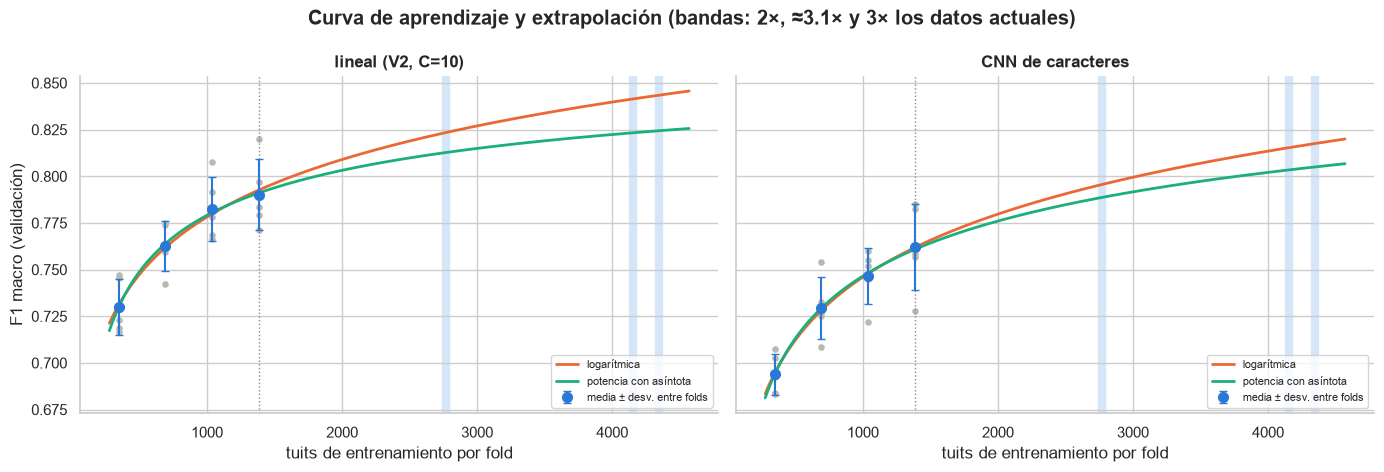

In [5]:
def f_log(n, a, b):
    return a + b * np.log(n)


def f_pow(n, a, b, c):
    return a - b * n ** (-c)


TARGETS = {"2×": 2 * n_full, "3×": 3 * n_full, "+3.7k tuits (≈3.1×)": n_full * (len(train) + 3700) / len(train)}


def fit_curves(n, y):
    """Ajusta las dos curvas. Con pocos puntos curve_fit avisa de que no puede estimar la covarianza; no se usa."""
    out = {}
    out["log"] = np.polyfit(np.log(n), y, 1)[::-1]  # (a, b)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            out["pow"] = curve_fit(f_pow, n, y, p0=(y.max() + 0.02, 1.0, 0.5), bounds=([0, 0, 0.01], [1, 1e4, 3]),
                                   maxfev=20000)[0]
    except RuntimeError:
        out["pow"] = None
    return out


def predict(params, kind, n):
    return f_log(n, *params) if kind == "log" else f_pow(n, *params)


rng = np.random.default_rng(SEED)
LC_RESULTS, rows = {}, []
for label in LC_MODELS:
    d = LC[LC["modelo"] == label]
    per_fold = d.groupby(["fracción", "fold"])["F1"].mean().unstack()  # fracciones × folds
    n = np.array([frac * n_full for frac in per_fold.index])
    point = fit_curves(n, per_fold.mean(axis=1).to_numpy())
    boots = {kind: {t: [] for t in TARGETS} for kind in ("log", "pow")}
    fails = 0
    for _ in range(2000):
        cols = rng.integers(0, per_fold.shape[1], per_fold.shape[1])
        fitted = fit_curves(n, per_fold.iloc[:, cols].mean(axis=1).to_numpy())
        for kind in ("log", "pow"):
            if fitted[kind] is None:
                fails += kind == "pow"
                continue
            base = predict(fitted[kind], kind, n_full)
            for t, nt in TARGETS.items():
                boots[kind][t].append(predict(fitted[kind], kind, nt) - base)
    LC_RESULTS[label] = {"n": n, "per_fold": per_fold, "point": point}
    for kind, name in [("log", "logarítmica"), ("pow", "potencia con asíntota")]:
        if point[kind] is None:
            continue
        row = {"modelo": label, "curva": name, "F1 al 100% (ajuste)": round(predict(point[kind], kind, n_full), 4)}
        if kind == "pow":
            row["techo a"] = round(point[kind][0], 4)
        for t in TARGETS:
            b = np.array(boots[kind][t])
            row[f"ganancia {t}"] = f"{np.median(b):+.4f} [{np.percentile(b, 5):+.4f}, {np.percentile(b, 95):+.4f}]"
        rows.append(row)
    print(f"{label}: ajustes de potencia que no convergen en el bootstrap: {fails} de 2000")
EXTRAP = pd.DataFrame(rows).set_index(["modelo", "curva"])
print("Ganancia de F1 macro frente al 100% actual: mediana [percentiles 5 y 95] del bootstrap")
display(EXTRAP)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
grid_n = np.linspace(0.2 * n_full, 3.3 * n_full, 200)
for ax, (label, res) in zip(axes, LC_RESULTS.items()):
    pf = res["per_fold"]
    for k in pf.columns:
        ax.scatter(res["n"], pf[k], color="#b9b8b2", s=14, zorder=2)
    ax.errorbar(res["n"], pf.mean(axis=1), yerr=pf.std(axis=1), fmt="o", color=COLORS[0], ms=7, capsize=3,
                label="media ± desv. entre folds", zorder=3)
    for (kind, name), c in zip([("log", "logarítmica"), ("pow", "potencia con asíntota")], COLORS[1:3]):
        if res["point"][kind] is not None:
            ax.plot(grid_n, predict(res["point"][kind], kind, grid_n), color=c, lw=2, label=name)
    ax.axvline(n_full, color="#8a8984", ls=":", lw=1)
    for t, nt in TARGETS.items():
        ax.axvline(nt, color="#d5e6f8", lw=6, zorder=0)
    ax.set(title=label, xlabel="tuits de entrenamiento por fold", ylabel="F1 macro (validación)" if ax is axes[0] else "")
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Curva de aprendizaje y extrapolación (bandas: 2×, ≈3.1× y 3× los datos actuales)", fontweight="bold")
fig.tight_layout()
savefig(fig, "learning_curve")
plt.show()

**Interpretación:**
- **Las dos curvas siguen subiendo al 100%, sin aplanarse:**
  - lineal: 0.7301 (25%) → 0.7628 → 0.7825 → 0.7902;
  - CNN de caracteres: 0.6940 → 0.7293 → 0.7467 → 0.7621.
  - El último tramo (75% → 100%) aún aporta +0.008 al lineal y +0.015 a la CNN.
- **Extrapolación con ≈3.7k tuits más del mismo tipo (≈3.1× por fold):**
  - lineal: +0.033 [+0.009, +0.042] con la curva de potencia y +0.051 [+0.046, +0.056] con la logarítmica;
  - CNN: +0.042 y +0.056;
  - con el doble de datos: lineal +0.022 / +0.031.
- **La incertidumbre real es mayor que esos intervalos.** El bootstrap solo recoge la variación entre folds, no la elección de la curva, y las dos curvas difieren ≈0.02 a 3×.
  - Además, el techo de la curva de potencia de la CNN se va al límite (1.0): con 4 puntos no se puede estimar.
  - Un rango razonable para el lineal es **+0.01 a +0.05**, con +0.03 como valor central.
- **Es, con diferencia, la palanca más grande del proyecto.** Supera al ensamble (+0.011) y a cualquiera de las mejoras de abajo.
  - La CNN gana más que el lineal: con más datos, las redes pesarían más en el ensamble.
  - Parte de la ganancia ya la recogen los modelos finales: se entrenan con los 1731 tuits, 1.25× lo que ve cada fold.
- **Condición para que valga:** los datos nuevos deben estar anotados con el mismo esquema (HS, TR y AG al estilo HatEval) y venir de la misma distribución.
  - Si el corpus de la competencia viene de HatEval (P4), un corpus externo de ese origen podría contener los tuits del test. Antes habría que medir el solapamiento (D35).

## 2. P2: entrenar AG sin las filas del artefacto

La regla D34 ya decide AG=1 en las 51 filas con comillas al predecir. Esas filas (26 son titulares neutros con AG=1 artificial, H3) solo pueden confundir al modelo de AG: le enseñan que un titular neutro es agresivo.

**Cambio:** el clasificador de AG se entrena **sin esas filas**, dentro de cada fold de entrenamiento. HS y TR siguen usándolas.
- **scikit-learn:** el estimador de AG se reentrena con el subconjunto (`exclude_quoted_ag=True`);
- **redes de cabeza compartida:** la pérdida de AG se pone a cero en esas filas (`ag_mask_quoted=True`), y la de HS y TR no cambia.

**Evaluación:** sobre **todas** las filas, con la regla aplicada a las del artefacto en los dos brazos (con y sin el cambio). El umbral de AG se elige sin esas filas, porque en ellas decide la regla.

**Criterio (fijado antes):**
- primero se prueba en el mejor lineal y en las 2 CNN; "mejora" si al menos 2 de los 3 ganan en F1 macro de media y en ≥ 4/5 folds;
- si mejora, se aplica a los 10 modelos del pool y se compara el stacking (FINAL_A) con y sin el cambio;
- **P2 se adopta** si el stacking gana de media y en ≥ 4/5 folds en `folds.csv` y gana de media en `folds_seed2`.

In [6]:
SCREEN = ["V2__logreg__nested", CNN_CHAR, CNN_WORD]
rows, wins = [], 0
for mid in SCREEN:
    kind, build = pool_spec(mid, True)
    PD["folds"][f"{mid}__p2"] = compute_oof(f"{mid}__p2", "folds", kind, build)
    base, new = evaluate([mid], "folds", quote=QUOTED), evaluate([f"{mid}__p2"], "folds", quote=QUOTED)
    s, d = delta_str(new, base)
    ok = d["Δ"] > 0 and d["folds a favor"] >= 4
    wins += ok
    rows.append({"modelo": mid, "F1 macro (todas las filas)": round(f1(base).mean(), 4), "F1 macro (P2)": round(f1(new).mean(), 4),
                 "Δ macro": s, "F1 AG (todas)": round(f1(base, "AG").mean(), 4), "F1 AG (P2)": round(f1(new, "AG").mean(), 4),
                 "mejora": ok})
display(pd.DataFrame(rows).set_index("modelo"))
P2_SCREEN_OK = wins >= 2
print(f"Modelos que mejoran: {wins} de 3 -> {'se aplica a todo el pool' if P2_SCREEN_OK else 'no se aplica al pool'}")

,F1 macro (todas las filas),F1 macro (P2),Δ macro,F1 AG (todas),F1 AG (P2),mejora
modelo,,,,,,
V2__logreg__nested,0.7968,0.7953,-0.0015 ± 0.0016 (1/5),0.7776,0.7731,False
V1__nn_cnn_char__tune-d0.3-lr0.002,0.7660,0.7626,-0.0034 ± 0.0142 (2/5),0.7439,0.7498,False
V1__nn_cnn_word__w2v,0.7726,0.7744,+0.0019 ± 0.0020 (4/5),0.7566,0.7589,True


Modelos que mejoran: 1 de 3 -> no se aplica al pool


In [7]:
P2_ADOPTED = False
if P2_SCREEN_OK:
    for fs in FOLDSETS:
        for mid in POOL07:
            kind, build = pool_spec(mid, True)
            PD[fs][f"{mid}__p2"] = compute_oof(f"{mid}__p2", fs, kind, build)
    rows = []
    for fs in FOLDSETS:
        base = evaluate(POOL07, fs, "stack-all", quote=QUOTED)
        new = evaluate([f"{m}__p2" for m in POOL07], fs, "stack-all", quote=QUOTED)
        s, d = delta_str(new, base)
        rows.append({"folds": fs, "FINAL_A con regla": round(f1(base).mean(), 4), "FINAL_A con regla + P2": round(f1(new).mean(), 4),
                     "Δ macro": s, "F1 AG": f"{f1(base, 'AG').mean():.4f} -> {f1(new, 'AG').mean():.4f}", "Δ": d})
    p2_tab = pd.DataFrame(rows).set_index("folds")
    display(p2_tab.drop(columns="Δ"))
    d1, d2 = p2_tab.loc["folds", "Δ"], p2_tab.loc["folds_seed2", "Δ"]
    P2_ADOPTED = d1["Δ"] > 0 and d1["folds a favor"] >= 4 and d2["Δ"] > 0
print(f"P2 adoptada: {P2_ADOPTED}")
EVAL_QUOTE = QUOTED if P2_ADOPTED else None
SUFFIX = "__p2" if P2_ADOPTED else ""
POOL_REF = [m + SUFFIX for m in POOL07]
E_REF = "V2__logreg__nested" + SUFFIX
ref_eval = {fs: evaluate(POOL07, fs, "stack-all", quote=EVAL_QUOTE) for fs in FOLDSETS}
print(f"Protocolo desde aquí: {'con la regla de comillas en los dos lados' if P2_ADOPTED else 'sin la regla'} | "
      f"pool de referencia: {'pool del 07 con P2' if P2_ADOPTED else 'pool del 07'} | "
      f"FINAL_A con este protocolo: {f1(ref_eval['folds']).mean():.4f} / {f1(ref_eval['folds_seed2']).mean():.4f}")

P2 adoptada: False
Protocolo desde aquí: sin la regla | pool de referencia: pool del 07 | FINAL_A con este protocolo: 0.8008 / 0.7961


**Interpretación: P2 no mejora, así que las filas del artefacto se quedan en el entrenamiento de AG.**
- **Lineal:** −0.0015 ± 0.0016 (1/5); el F1 de AG baja de 0.7776 a 0.7731.
- **CNN de caracteres:** −0.0034 ± 0.0142 (2/5).
- **CNN de palabras:** +0.0019 ± 0.0020 (4/5).
- Solo mejora 1 de los 3 modelos, así que, por la regla fijada, no se aplica al pool. **P2 queda resuelta: no se excluyen.**
- **Por qué no ayuda (hipótesis):** de las 51 filas, 25 tienen HS=1 y su AG=1 es plausible (combinaciones 101 y 111). Quitarlas elimina ejemplos positivos reales de AG. Los 26 titulares neutros no parecen confundir al modelo: la regla los acierta de todos modos y el umbral de AG se elige sin ellos.
- **Desde aquí,** las comparaciones siguen sin la regla de comillas, como estaba previsto.

## 3. Especialización por etiqueta

**Lo que ya hay:** los modelos actuales **ya son binarios por etiqueta**. Por dentro entrenan un clasificador para HS, otro para TR y otro para AG. Pero los tres comparten la misma variante de preprocesamiento, la misma representación y los mismos hiperparámetros. Lo nuevo es **especializarlos**:

- **a) Configuración por etiqueta:** cada etiqueta elige por su cuenta variante (V1, V2, V3) y representación (palabras + caracteres, solo caracteres, palabras + caracteres + rasgos hechos a mano, solo palabras). Son 10 configuraciones por etiqueta, con la regresión logística elasticnet y C=10 (la elección del 04). La elección se hace con una CV anidada: 3 folds internos dentro de cada fold externo. Se compara con la configuración común (la logística V2 del pool).
- **b) Modelo condicional:**
  - un **modelo condicional** aprende una etiqueta sabiendo que otra vale 1. Aquí, TR|HS se entrena **solo con los tuits de odio** (HS=1) y responde "¿va contra una persona concreta o contra un colectivo?" (H10);
  - como TR=1 implica HS=1 (H2), P(TR) = P(HS) · P(TR|HS). Igual con AG: P(AG) = P(HS) · P(AG|HS), con AG|HS entrenado sin las filas del artefacto;
  - HS se entrena con todas las filas. Todos con la configuración común.
- **c) Label powerset:**
  - un único clasificador **multiclase** cuyas clases son las **combinaciones** de etiquetas (000, 100, 101, 110, 111, 001);
  - la probabilidad de cada etiqueta se obtiene **marginalizando**: P(HS) = P(100) + P(101) + P(110) + P(111), y así con TR y AG;
  - captura las dependencias entre etiquetas de forma directa;
  - es una regresión logística L2 multinomial con la configuración común.

Cada uno se evalúa solo (frente a la logística V2 del pool) y como miembro nuevo del stacking (frente a FINAL_A), en `folds.csv`.

In [8]:
NEW = {f"V2__labelwise{SUFFIX}": ("labelwise", lambda: P2_ADOPTED),
       "V2__conditional": ("sk", lambda: lw.ConditionalClassifier()),
       "V2__powerset": ("sk", lambda: lw.PowersetClassifier())}
for name, (kind, build) in NEW.items():
    PD["folds"][name] = compute_oof(name, "folds", kind, build)


def single_row(name, label=None):
    r, e = evaluate([name], "folds", quote=EVAL_QUOTE), evaluate([E_REF], "folds", quote=EVAL_QUOTE)
    s, _ = delta_str(r, e)
    row = {"modelo": label or name, **{f"F1 {lab}": round(f1(r, lab).mean(), 4) for lab in LABELS},
           "F1 macro": round(f1(r).mean(), 4), "Δ vs logística V2": s}
    if name == E_REF:
        return row | {"correlación de errores con la logística V2": "—", "stacking + este modelo": "—", "Δ stacking": "—"}
    stack = evaluate(POOL_REF + [name], "folds", "stack-all", quote=EVAL_QUOTE)
    s2, _ = delta_str(stack, evaluate(POOL_REF, "folds", "stack-all", quote=EVAL_QUOTE))
    corr = np.corrcoef((r["pred"] != Y).ravel(), (e["pred"] != Y).ravel())[0, 1]
    return row | {"correlación de errores con la logística V2": round(corr, 3), "stacking + este modelo": round(f1(stack).mean(), 4),
                  "Δ stacking": s2}


rows = [single_row(E_REF, f"{E_REF} (configuración común)")] + [single_row(n) for n in NEW]
SPEC = pd.DataFrame(rows).set_index("modelo")
display(SPEC)
configs = json.loads((CACHE_DIR / f"V2__labelwise{SUFFIX}__folds__configs.json").read_text())
print("Configuración elegida por etiqueta en cada fold (variante / representación):")
display(pd.DataFrame([{lab: f"{c[lab]['variant']} / {c[lab]['features']}" for lab in LABELS} for c in configs],
                     index=[f"fold {k}" for k in range(len(configs))]))

,F1 HS,F1 TR,F1 AG,F1 macro,Δ vs logística V2,correlación de errores con la logística V2,stacking + este modelo,Δ stacking
modelo,,,,,,,,
V2__logreg__nested (configuración común),0.7805,0.8324,0.7576,0.7902,+0.0000 ± 0.0000 (0/5),—,—,—
V2__labelwise,0.7774,0.8199,0.7663,0.7879,-0.0023 ± 0.0049 (1/5),0.919,0.7983,-0.0025 ± 0.0058 (1/5)
V2__conditional,0.7805,0.8227,0.7423,0.7818,-0.0083 ± 0.0045 (0/5),0.849,0.7976,-0.0032 ± 0.0054 (1/5)
V2__powerset,0.7861,0.8102,0.7423,0.7795,-0.0107 ± 0.0073 (0/5),0.748,0.7999,-0.0009 ± 0.0039 (2/5)


Configuración elegida por etiqueta en cada fold (variante / representación):


,HS,TR,AG
fold 0,V1 / tfidf,V1 / tfidf,V1 / tfidf
fold 1,V1 / tfidf,V1 / tfidf+hand,V3 / tfidf
fold 2,V1 / tfidf,V2 / word,V1 / tfidf
fold 3,V3 / tfidf,V1 / tfidf,V3 / tfidf
fold 4,V1 / tfidf,V2 / tfidf+hand,V1 / tfidf


**Interpretación: ninguna especialización mejora, ni sola ni dentro del stacking.**
- **a) Configuración por etiqueta:** 0.7879, −0.0023 ± 0.0049 (1/5).
  - AG sube (0.7663 frente a 0.7576), pero HS y TR bajan.
  - La configuración elegida cambia de un fold a otro, sobre todo en TR (V1 / palabras + caracteres, V1 / + rasgos, V2 / solo palabras…). Es la firma de una selección que persigue ruido con ≈900 tuits por fold interno.
- **b) Condicional:** 0.7818, −0.0083 ± 0.0045 (0/5).
  - TR baja (0.8227 frente a 0.8324) y AG también (0.7423 frente a 0.7576).
  - Entrenar TR|HS y AG|HS solo con los ≈600 tuits de odio de cada fold quita datos, y multiplicar P(HS)·P(TR|HS) acumula los errores de HS.
- **c) Label powerset:** 0.7795, −0.0107 ± 0.0073 (0/5).
  - Es el mejor en HS (0.7861), pero TR y AG empeoran: las combinaciones raras (001: 26 tuits; 110: 28) tienen muy pocos ejemplos.
- **Como miembro del stacking,** los tres restan algo (−0.0009 a −0.0032). Sus errores se parecen mucho a los de la logística (correlación 0.75–0.92), y el stacking con las 3 etiquetas ya aprovecha la dependencia entre ellas (H53).

## 4. Más semillas en las redes

Las redes son lo que más aporta al ensamble (H52), y cada una es la media de 3 redes con semillas distintas. Con **10 semillas** la media es más estable. Se entrenan las 2 CNN del pool con 10 semillas y una variante nueva, la CNN de caracteres sobre V3 (texto con restauración). Si P2 se adoptó, se entrenan con la pérdida de AG enmascarada.

**Comprobación:** las 3 primeras semillas de cada CNN con 10 son exactamente las mismas que las de la versión con 3 (misma semilla base y misma validación interna), así que su media debe reproducir las OOF del pool.

**Hardware:** se usa GPU si la hay (CUDA con la arquitectura de la tarjeta en `torch.cuda.get_arch_list()`). GPU y CPU no dan resultados idénticos bit a bit, así que las cifras de una y otra no son comparables al decimal.

In [9]:
N_SEEDS_MORE = 10
cuda = torch.cuda.is_available()
print(f"CUDA disponible: {cuda}" + (f" | {torch.cuda.get_device_name(0)} | arquitecturas: {torch.cuda.get_arch_list()}" if cuda else
      " -> se entrena en CPU (las redes de neural.py usan CPU; Apple MPS no se usa)"))
SEEDED = {f"{CNN_CHAR}__s10{SUFFIX}": CNN_CHAR, f"{CNN_WORD}__s10{SUFFIX}": CNN_WORD,
          f"V3__nn_cnn_char__tune-d0.3-lr0.002__s10{SUFFIX}": CNN_CHAR}
for name, base in SEEDED.items():
    variant = "V3" if name.startswith("V3__") else None
    changes = dict(n_seeds=N_SEEDS_MORE, ag_mask_quoted=P2_ADOPTED, **({"variant": variant} if variant else {}))
    PD["folds"][name] = compute_oof(name, "folds", "net", lambda base=base, changes=changes: nn_.NeuralTweetClassifier(
        **net_params(base, **changes)))

rows = []
for name, base in SEEDED.items():
    seeds = np.load(CACHE_DIR / f"{name}__folds__seeds.npy")
    first3 = seeds[:3].mean(axis=0)
    same_model = not name.startswith("V3__")
    per_seed = [f1(en.crossfit(en.Single(0), s[:, None, :], Y, folds, EMPTY_TR, quote=EVAL_QUOTE)).mean() for s in seeds]
    r3 = en.crossfit(en.Single(0), first3[:, None, :], Y, folds, EMPTY_TR, quote=EVAL_QUOTE)
    r10 = evaluate([name], "folds", quote=EVAL_QUOTE)
    s, _ = delta_str(r10, r3)
    rows.append({"modelo": name, "3 primeras = OOF del pool": (float(np.abs(first3 - PD["folds"][base + SUFFIX]).max()) if same_model else "—"),
                 "F1 por semilla (mín.–máx.)": f"{min(per_seed):.4f}–{max(per_seed):.4f}",
                 "F1 media de 3": round(f1(r3).mean(), 4), "F1 media de 10": round(f1(r10).mean(), 4), "Δ (10 − 3)": s})
display(pd.DataFrame(rows).set_index("modelo"))

pool_s10 = [f"{CNN_CHAR}__s10{SUFFIX}" if m == CNN_CHAR + SUFFIX else f"{CNN_WORD}__s10{SUFFIX}" if m == CNN_WORD + SUFFIX else m
            for m in POOL_REF]
base_stack = evaluate(POOL_REF, "folds", "stack-all", quote=EVAL_QUOTE)
rows = []
for label, ids in [("CNN con 10 semillas en lugar de 3", pool_s10),
                   ("+ CNN de caracteres V3 (10 semillas)", pool_s10 + [f"V3__nn_cnn_char__tune-d0.3-lr0.002__s10{SUFFIX}"])]:
    r = evaluate(ids, "folds", "stack-all", quote=EVAL_QUOTE)
    s, _ = delta_str(r, base_stack)
    rows.append({"stacking": label, "F1 macro": round(f1(r).mean(), 4), "Δ vs pool de referencia": s})
display(pd.DataFrame(rows).set_index("stacking"))

CUDA disponible: False -> se entrena en CPU (las redes de neural.py usan CPU; Apple MPS no se usa)


,3 primeras = OOF del pool,F1 por semilla (mín.–máx.),F1 media de 3,F1 media de 10,Δ (10 − 3)
modelo,,,,,
V1__nn_cnn_char__tune-d0.3-lr0.002__s10,0.0,0.7305–0.7589,0.7621,0.7721,+0.0099 ± 0.0115 (4/5)
V1__nn_cnn_word__w2v__s10,0.0,0.7459–0.7652,0.7635,0.7644,+0.0009 ± 0.0059 (2/5)
V3__nn_cnn_char__tune-d0.3-lr0.002__s10,—,0.7349–0.7544,0.7630,0.7628,-0.0002 ± 0.0127 (3/5)


,F1 macro,Δ vs pool de referencia
stacking,,
CNN con 10 semillas en lugar de 3,0.8022,+0.0014 ± 0.0075 (4/5)
+ CNN de caracteres V3 (10 semillas),0.8015,+0.0007 ± 0.0093 (4/5)


**Interpretación:**
- **Comprobación:** las 3 primeras semillas reproducen exactamente (diferencia 0.0) las OOF de las CNN del pool.
- **CNN de caracteres:** con 10 semillas pasa de 0.7621 a 0.7721, +0.0099 ± 0.0115 (4/5). Es la mayor mejora individual de este notebook. Cada semilla por separado da 0.7305–0.7589, así que promediar importa mucho en esta red.
- **CNN de palabras:** +0.0009 (2/5), casi nada. La inicialización con Word2Vec ya la estabiliza (H39).
- **CNN de caracteres sobre V3** (10 semillas): 0.7628, igual que la V1 con 3.
- **En el stacking,** cambiar las CNN por sus versiones de 10 semillas suma +0.0014 ± 0.0075 (4/5), y añadir la V3, +0.0007. El stacker ya compensa buena parte del ruido de semilla.
- **Hardware:** todo se entrenó en CPU; no hay CUDA en esta máquina.

## 5. Gemelos del test (P6)

**Gemelos:** tuits con el mismo texto normalizado (minúsculas, sin menciones, URLs ni signos; `_near_duplicate_key`, como en el 01). Hay 21 tuits del test con un gemelo en el train. La idea es copiarles la etiqueta del gemelo en lugar de la predicción.

**Riesgo:** hay gemelos con etiquetas contradictorias (H13, *"Tu eres mi perra"* anotado 000 y 111). Por eso la etiqueta del gemelo es la **mayoría** de su grupo, y los grupos con empate no se copian.

**Evaluación en CV:**
- `make_folds` pone los gemelos del train en el mismo fold, así que cada tuit con gemelo se compara con la etiqueta de sus gemelos, que es lo que se copiaría si estuvieran en el train;
- se mide el F1 macro de las decisiones fuera de fold de FINAL_A, con y sin copiar.

**Criterio (fijado antes):** se adopta si copiar sube el F1 macro de media en los dos conjuntos de folds y acierta más etiquetas que el modelo en los tuits con gemelo.

In [10]:
keys = pd.Series([_near_duplicate_key(t) for t in texts])
groups = {k: list(idx) for k, idx in keys.groupby(keys).groups.items() if len(idx) >= 2}
twin_rows = sorted(i for idx in groups.values() for i in idx)
contradictory = sum(len({tuple(Y[i]) for i in idx}) > 1 for idx in groups.values())
print(f"Train: {len(groups)} grupos de gemelos ({len(twin_rows)} tuits); con etiquetas contradictorias: {contradictory}")

rows = []
for fs, f in FOLDSETS.items():
    r = ref_eval[fs]
    pred, copied = r["pred"].copy(), r["pred"].copy()
    n_copy = 0
    for idx in groups.values():
        for i in idx:
            others = Y[[j for j in idx if j != i]].mean(axis=0)
            if np.any(others == 0.5):
                continue
            copied[i] = (others > 0.5).astype(int)
            n_copy += 1
    base = pd.DataFrame([en.metrics(Y[f == k], pred[f == k]) for k in sorted(np.unique(f))])
    new = pd.DataFrame([en.metrics(Y[f == k], copied[f == k]) for k in sorted(np.unique(f))])
    d = en.paired_delta(new["F1_macro"], base["F1_macro"])
    tw = np.array(twin_rows)
    rows.append({"folds": fs, "tuits copiados": n_copy,
                 "etiquetas acertadas en gemelos: modelo": f"{(pred[tw] == Y[tw]).mean():.3f}",
                 "copiando": f"{(copied[tw] == Y[tw]).mean():.3f}",
                 "F1 macro (modelo)": round(base["F1_macro"].mean(), 4), "F1 macro (copiando)": round(new["F1_macro"].mean(), 4),
                 "Δ": f"{d['Δ']:+.4f} ± {d['Δ desv.']:.4f} ({d['folds a favor']}/5)", "_d": d["Δ"],
                 "_acc": (copied[tw] == Y[tw]).mean() > (pred[tw] == Y[tw]).mean()})
twins = pd.DataFrame(rows).set_index("folds")
display(twins.drop(columns=["_d", "_acc"]))
TWINS_ADOPTED = bool((twins["_d"] > 0).all() and twins["_acc"].all())
TWIN_TABLE = en.twin_table(texts, Y)
test_keys = [_near_duplicate_key(t) for t in test["text"]]
in_train = [k in TWIN_TABLE for k in test_keys]
fa_test = pd.read_csv(md.SUBMISSIONS_DIR / "FINAL_A_ens07__D__stack-all.csv")[LABELS].to_numpy()
agree = [fa_test[i].tolist() == TWIN_TABLE[k] for i, k in enumerate(test_keys) if k in TWIN_TABLE]
print(f"Test: {sum(in_train)} tuits con gemelo en el train (con etiqueta no empatada) | FINAL_A coincide con el gemelo en "
      f"{sum(agree)} de {len(agree)} | P6 adoptada: {TWINS_ADOPTED}")

Train: 10 grupos de gemelos (32 tuits); con etiquetas contradictorias: 1


,tuits copiados,etiquetas acertadas en gemelos: modelo,copiando,F1 macro (modelo),F1 macro (copiando),Δ
folds,,,,,,
folds,32,0.969,0.938,0.8008,0.7998,-0.0010 ± 0.0021 (0/5)
folds_seed2,32,0.969,0.938,0.7961,0.7952,-0.0009 ± 0.0020 (0/5)


Test: 21 tuits con gemelo en el train (con etiqueta no empatada) | FINAL_A coincide con el gemelo en 21 de 21 | P6 adoptada: False


**Interpretación: P6 no se adopta.**
- **En el train** hay 10 grupos de gemelos (32 tuits), uno con etiquetas contradictorias (H13).
- **Copiar la etiqueta acierta menos que el modelo:** 0.938 frente a 0.969 de las etiquetas de esos tuits. El F1 macro baja −0.0010 (0/5) en `folds.csv` y −0.0009 (0/5) en `folds_seed2`.
- **En el test daría igual:** los 21 tuits con gemelo en el train ya reciben de FINAL_A exactamente la etiqueta del gemelo (21 de 21).
- **P6 queda resuelta: no hace falta ninguna regla.**

## 6. Nuevo ensamble (pool v2)

**Definición del pool v2** (fijada aquí, antes de mirar el stacking):
1. el pool del 07, en su versión con P2 si P2 se adoptó;
2. las 2 CNN del pool se **sustituyen** por sus versiones con 10 semillas. Es el mismo modelo con más semillas, y tener las dos versiones duplicaría la información;
3. se **añade** cada modelo nuevo que, por sí solo, quede a menos de 0.04 del mejor lineal en F1 macro **o** tenga una correlación de errores < 0.65 con él (en `folds.csv`). Los candidatos son la configuración por etiqueta, el condicional, el powerset y la CNN de caracteres V3.

**Protocolo y regla del 07, sin cambios:**
- el método es el del FINAL_A: stacking con los logits de las 3 etiquetas;
- se compara con FINAL_A con el mismo protocolo (con la regla en los dos lados si P2 se adoptó; sin ella si no);
- se adopta si Δ ≥ +0.005 y es positiva en ≥ 4/5 folds, en `folds.csv` **y** en `folds_seed2`.

Se generan las OOF de `folds_seed2` que falten.

In [11]:
CANDIDATES = [f"V2__labelwise{SUFFIX}", "V2__conditional", "V2__powerset", f"V3__nn_cnn_char__tune-d0.3-lr0.002__s10{SUFFIX}"]
e_ref = evaluate([E_REF], "folds", quote=EVAL_QUOTE)
rows, ADDED = [], []
for name in CANDIDATES:
    r = evaluate([name], "folds", quote=EVAL_QUOTE)
    gap = f1(e_ref).mean() - f1(r).mean()
    corr = np.corrcoef((r["pred"] != Y).ravel(), (e_ref["pred"] != Y).ravel())[0, 1]
    ok = gap < 0.04 or corr < 0.65
    ADDED += [name] if ok else []
    rows.append({"candidato": name, "F1 macro": round(f1(r).mean(), 4), "distancia al mejor lineal": round(gap, 4),
                 "correlación de errores": round(corr, 3), "entra": ok})
display(pd.DataFrame(rows).set_index("candidato"))
POOL_V2 = pool_s10 + ADDED
print(f"Pool v2 ({len(POOL_V2)} modelos): {POOL_V2}")

SPECS = {f"{m}__p2": pool_spec(m, True) for m in POOL07}
SPECS.update(NEW)
for name, base in SEEDED.items():
    variant = "V3" if name.startswith("V3__") else None
    changes = dict(n_seeds=N_SEEDS_MORE, ag_mask_quoted=P2_ADOPTED, **({"variant": variant} if variant else {}))
    SPECS[name] = ("net", lambda base=base, changes=changes: nn_.NeuralTweetClassifier(**net_params(base, **changes)))
missing = [m for m in POOL_V2 if m not in PD["folds_seed2"]]
print(f"OOF de folds_seed2 por calcular: {missing}")
for m in missing:
    PD["folds_seed2"][m] = compute_oof(m, "folds_seed2", *SPECS[m])

rows, D2 = [], {}
for fs in FOLDSETS:
    cand = evaluate(POOL_V2, fs, "stack-all", quote=EVAL_QUOTE)
    s, d = delta_str(cand, ref_eval[fs])
    D2[fs] = d
    rows.append({"folds": fs, "FINAL_A": round(f1(ref_eval[fs]).mean(), 4), "pool v2 (stacking)": round(f1(cand).mean(), 4),
                 "micro": round(f1(cand, "micro").mean(), 4), "Δ": s,
                 "cumple": d["Δ"] >= 0.005 and d["folds a favor"] >= 4})
decision = pd.DataFrame(rows).set_index("folds")
display(decision)
A2_ADOPTED = bool(decision["cumple"].all())
print(f"Se adopta el pool v2 (FINAL_A2): {'SÍ' if A2_ADOPTED else 'NO: FINAL_A se mantiene'}")

,F1 macro,distancia al mejor lineal,correlación de errores,entra
candidato,,,,
V2__labelwise,0.7879,0.0023,0.919,True
V2__conditional,0.7818,0.0083,0.849,True
V2__powerset,0.7795,0.0107,0.748,True
V3__nn_cnn_char__tune-d0.3-lr0.002__s10,0.7628,0.0274,0.606,True


Pool v2 (14 modelos): ['V2__logreg__nested', 'V1__logreg__nested', 'V3__linsvm__nested', 'V3__et__word__k2000', 'V3__xgb__word__k500', 'V3__nbsvm', 'V3__mnb__word', 'V1__nn_cnn_char__tune-d0.3-lr0.002__s10', 'V1__nn_cnn_word__w2v__s10', 'V3__nn_mlp__tune-d0.5-lr0.002', 'V2__labelwise', 'V2__conditional', 'V2__powerset', 'V3__nn_cnn_char__tune-d0.3-lr0.002__s10']
OOF de folds_seed2 por calcular: ['V1__nn_cnn_char__tune-d0.3-lr0.002__s10', 'V1__nn_cnn_word__w2v__s10', 'V2__labelwise', 'V2__conditional', 'V2__powerset', 'V3__nn_cnn_char__tune-d0.3-lr0.002__s10']


,FINAL_A,pool v2 (stacking),micro,Δ,cumple
folds,,,,,
folds,0.8008,0.8019,0.7989,+0.0011 ± 0.0065 (3/5),False
folds_seed2,0.7961,0.8003,0.7975,+0.0042 ± 0.0045 (4/5),False


Se adopta el pool v2 (FINAL_A2): NO: FINAL_A se mantiene


In [12]:
def _fit_final(name, kind, build_args):
    """Entrena el modelo final de un miembro con todo el train, lo guarda en models/09_mejoras/ y devuelve
    sus probabilidades en el test (se ejecuta en un proceso aparte)."""
    import labelwise as lw_
    import modeling as md_

    kind_, spec = build_args
    if kind_ == "net":
        import neural as nn__  # solo aquí: torch no puede cargarse en un proceso que va a usar xgboost (D33)

        params, epochs = spec
        params = dict(params, fixed_epochs=epochs, n_threads=FINAL_THREADS)
        model = nn__.NeuralTweetClassifier(**params).fit(texts, Y)
        nn__.save_neural_model(model, name, {"notebook": "09"}, notebook="09")
    elif kind_ == "nested":
        variant, clf, feats, kw, params = spec
        model = md_.TweetToxicClassifier(variant=variant, classifier=clf, features=feats, clf_params=params, **kw).fit(texts, Y)
        md_.save_model(model, name, {"notebook": "09", "clf_params_from": "04 (CV en todo el train)"}, notebook="09")
    elif kind_ == "labelwise":
        configs, _ = lw_.select_label_configs(texts, Y, exclude_quoted_ag=spec, n_jobs=3)
        model = lw_.LabelwiseClassifier(configs, exclude_quoted_ag=spec).fit(texts, Y)
        lw_.save_labelwise(model, name, {"notebook": "09", "configs": configs})
    else:
        model = spec.fit(texts, Y)
        if isinstance(model, md_.TweetToxicClassifier):
            md_.save_model(model, name, {"notebook": "09"}, notebook="09")
        else:
            lw_.save_labelwise(model, name, {"notebook": "09"})
    return model.predict_proba(test["text"])


FINALS09 = {}
if A2_ADOPTED:
    P_TEST = {m: stored(test_store, m, test["id"]) for m in POOL07}
    order = sorted([m for m in POOL_V2 if m not in P_TEST], key=lambda m: SPECS[m][0] == "net")  # primero scikit-learn
    for name in order:
        kind, build = SPECS[name]
        if kind == "net":
            params = build().get_params()
            epochs = json.loads((CACHE_DIR / f"{name}__folds__epochs.json").read_text())
            args = (kind, (params, epochs))
        elif kind == "nested":
            variant, clf, feats, kw = build()
            base = name.replace("__p2", "")
            args = (kind, (variant, clf, feats, kw, json.loads(REG.loc[base, "params"])))
        elif kind == "labelwise":
            args = (kind, build())
        else:
            args = (kind, build())
        start = time.perf_counter()
        print(f"  final {name} ...", end=" ", flush=True)
        P_TEST[name] = in_worker(_fit_final, name, kind, args)
        print(f"{time.perf_counter() - start:.0f} s", flush=True)

    res_v2 = evaluate(POOL_V2, "folds", "stack-all", quote=EVAL_QUOTE)
    P_main = np.stack([PD["folds"][m] for m in POOL_V2], axis=1)
    fitted, thr = en.fit_final(en.Stacking(own_label_only=False), P_main, Y, folds, res_v2["proba"], quote=EVAL_QUOTE)
    cv_info = {fs: round(f1(evaluate(POOL_V2, fs, "stack-all", quote=EVAL_QUOTE)).mean(), 4) for fs in FOLDSETS}
    for tag, quote_rule in [("FINAL_A2", False), ("FINAL_A2_quote", True)]:
        name = "ens09__v2__stack-all" + ("__quote" if quote_rule else "")
        model = en.EnsembleClassifier(POOL_V2, fitted, thr, name=name, quote_rule=quote_rule)
        path = en.save_ensemble(model, name, {"notebook": "09", "role": tag, "pool": POOL_V2, "p2": P2_ADOPTED,
                                              "cv_F1_macro": cv_info, "protocol_with_quote_rule": P2_ADOPTED, "seed": SEED})
        FINALS09[tag] = {"name": name, "model": model, "path": path}
    print("Umbrales del ensamble v2:", thr)

In [13]:
if A2_ADOPTED:
    P_te = np.stack([P_TEST[m] for m in POOL_V2], axis=1)
    files, subs = {}, {}
    for tag, F in FINALS09.items():
        files[tag] = md.make_submission(F["name"], filename=f"{tag}_{F['name']}")
        subs[tag] = pd.read_csv(files[tag])
        expected = md.decide(F["model"].predict_proba_from_base(P_te), test["text"], F["model"].thresholds)
        if F["model"].quote_rule:
            expected[QUOTED_TE, AG] = 1
        assert (subs[tag][LABELS].to_numpy() == expected).all(), f"{tag}: el archivo no coincide con las probabilidades guardadas"
    diff = subs["FINAL_A2_quote"][LABELS].to_numpy() != subs["FINAL_A2"][LABELS].to_numpy()
    assert not diff[:, :AG].any() and not diff[~QUOTED_TE].any()
    fa_quote = pd.read_csv(md.SUBMISSIONS_DIR / "FINAL_A_quote_ens08__D__stack-all__quote.csv")[LABELS].to_numpy()
    d_a = subs["FINAL_A2_quote"][LABELS].to_numpy() != fa_quote
    display(pd.DataFrame([{"envío": tag, "archivo": f"{p.parent.name}/{p.name}", "filas": len(subs[tag]),
                           "ids en orden": bool((subs[tag]["id"] == test["id"]).all()),
                           "valores": sorted(np.unique(subs[tag][LABELS]).tolist()), "nulos": int(subs[tag].isna().sum().sum()),
                           **{f"% {lab}=1": round(100 * subs[tag][lab].mean(), 1) for lab in LABELS}}
                          for tag, p in files.items()]).set_index("envío"))
    print(f"FINAL_A2_quote frente a FINAL_A_quote: difieren {int(d_a.any(axis=1).sum())} tuits "
          f"({', '.join(f'{lab}: {int(d_a[:, j].sum())}' for j, lab in enumerate(LABELS))}); "
          f"FINAL_A2_quote frente a FINAL_A2: solo AG en {int(diff[:, AG].sum())} tuits con la regla")
    # Registro: el ensamble y los modelos base nuevos
    reg_rows, oof_frames, test_frames = [], [], []
    for name in [m for m in POOL_V2 if m not in POOL07] + [FINALS09["FINAL_A2"]["name"]]:
        is_ens = name.startswith("ens09")
        oof = res_v2["proba"] if is_ens else PD["folds"][name]
        proba_te = FINALS09["FINAL_A2"]["model"].predict_proba_from_base(P_te) if is_ens else P_TEST[name]
        t = evaluate([name], "folds", quote=EVAL_QUOTE)["folds"][("plateau", True)] if not is_ens else res_v2["folds"][("plateau", True)]
        found = md.find_model_path(name)
        base_id = name.replace("__p2", "").replace("__s10", "")
        family = ("ensamble" if is_ens else REG.loc[base_id, "family"] if base_id in REG.index
                  else "neuronal" if "__nn_" in name else "lineal")
        reg_rows.append({"model_id": name, "family": family,
                         "classifier": "stack-all" if is_ens else name.split("__")[1], "variant": name.split("__")[0] if not is_ens else "—",
                         "features": "pool v2: " + " + ".join(POOL_V2) if is_ens else "09", "params": "{}", "notebook": "09",
                         "F1_macro": round(t["F1_macro"].mean(), 4), "F1_macro_std": round(t["F1_macro"].std(), 4),
                         "F1_micro": round(t["F1_micro"].mean(), 4), **{f"F1_{lab}": round(t[f"F1_{lab}"].mean(), 4) for lab in LABELS},
                         "proba_calibrated": is_ens, "saved": found is not None,
                         "size_mb": round(found.stat().st_size / 1e6, 2) if found else None})
        oof_frames.append(md.prediction_frame(name, train["id"], oof, folds))
        test_frames.append(md.prediction_frame(name, test["id"], proba_te))
    reg = md.update_registry(reg_rows)
    md.update_predictions(oof_frames, md.OOF_PATH)
    md.update_predictions(test_frames, md.TEST_PRED_PATH)
    print(f"Registro: {len(reg)} modelos | añadidos: {[r['model_id'] for r in reg_rows]}")
else:
    print("FINAL_A se mantiene: no se generan envíos nuevos.")

FINAL_A se mantiene: no se generan envíos nuevos.


In [14]:
# P6: si se adoptó, un envío adicional = el final 1 + la etiqueta del gemelo en los tuits del test que lo tienen.
# Solo difiere del final 1 en esos tuits, así que su puntaje se puede comparar limpiamente (como en el 08).
if TWINS_ADOPTED:
    base_name = FINALS09["FINAL_A2_quote"]["name"] if A2_ADOPTED else "ens08__D__stack-all__quote"
    base = md.load_model(base_name)
    tw_name = base_name.replace("ens07", "ens09").replace("ens08", "ens09") + "__twins"
    model_tw = en.EnsembleClassifier(base.base_ids, base.combiner, base.thresholds, name=tw_name, quote_rule=True,
                                     twin_table=TWIN_TABLE)
    en.save_ensemble(model_tw, tw_name, {"notebook": "09", "role": "final 1 + gemelos (P6)", "base": base_name, "seed": SEED})
    tag = "FINAL_A2_quote_twins" if A2_ADOPTED else "FINAL_A_quote_twins"
    p_tw = md.make_submission(tw_name, filename=f"{tag}_{tw_name}")
    base_file = (md.SUBMISSIONS_DIR / f"FINAL_A2_quote_{base_name}.csv") if A2_ADOPTED else \
        (md.SUBMISSIONS_DIR / "FINAL_A_quote_ens08__D__stack-all__quote.csv")
    d_tw = pd.read_csv(p_tw)[LABELS].to_numpy() != pd.read_csv(base_file)[LABELS].to_numpy()
    assert not d_tw[~np.array(in_train)].any(), "difiere fuera de los tuits con gemelo"
    print(f"{p_tw.name}: difiere de {base_file.name} en {int(d_tw.any(axis=1).sum())} tuits, todos con gemelo en el train")
else:
    print("P6 no se adopta: no hay envío con gemelos.")

P6 no se adopta: no hay envío con gemelos.


**Interpretación: el pool v2 no cumple la regla, así que FINAL_A se mantiene y no se generan envíos nuevos.**
- **Composición:** entran los 4 candidatos (configuración por etiqueta, condicional, powerset y CNN V3), porque todos quedan a menos de 0.04 del mejor lineal. El pool v2 tiene 14 modelos.
- **`folds.csv`:** el stacking del pool v2 da 0.8019 frente a 0.8008, +0.0011 ± 0.0065 (3/5).
- **`folds_seed2`:** 0.8003 frente a 0.7961, +0.0042 ± 0.0045 (4/5).
- **Ninguno llega a +0.005 ni a 4/5 folds en los dos conjuntos.** La mejora existe, pero es del tamaño del ruido, coherente con que cada mejora individual fue ≤ +0.01 en un modelo y ≈0 en el stacking.

## 7. Envíos finales (árbol fijado antes de subir nada)

- **Si FINAL_A2 se adoptó por la regla de CV:** los finales pasan a ser **FINAL_A2_quote + FINAL_A_quote**.
  - La regla de comillas ya está validada en el leaderboard (H58), así que los dos llevan la regla.
  - El segundo final cubre ahora el riesgo del **cambio de modelo**: si el ensamble nuevo rindiera peor en la parte privada, queda el anterior.
- **Si no se adoptó:** siguen **FINAL_A_quote + FINAL_A** (D36).
- **No se elige por el leaderboard público** (H44): una diferencia de ≈0.01 entre modelos distintos está dentro del ruido de la parte pública. El puntaje de FINAL_A2_quote solo se anota.

In [15]:
FINALS = ["FINAL_A2_quote", "FINAL_A_quote"] if A2_ADOPTED else ["FINAL_A_quote", "FINAL_A"]
print("Envíos finales:", " + ".join(FINALS))

Envíos finales: FINAL_A_quote + FINAL_A


## 8. Conclusiones

1. **Más datos es la única palanca grande que queda.**
   - La curva de aprendizaje no está plana.
   - Con ≈3.7k tuits más del mismo tipo, el lineal ganaría del orden de +0.03 (rango razonable +0.01 a +0.05) y la CNN algo más.
   - Es el triple de lo que aportó el ensamble.
   - Vale la pena pedir autorización para un corpus externo **etiquetado con el mismo esquema**, midiendo antes su solapamiento con el train y el test (P4, D35).
2. **Con los datos actuales, las mejoras probadas no superan el ruido:**
   - P2 (excluir el artefacto al entrenar AG): no mejora (1 de 3 modelos); resuelta, no se excluye;
   - especialización por etiqueta (configuración propia, condicional, powerset): todas peores solas (−0.002 a −0.011) y neutras o negativas en el stacking;
   - 10 semillas: +0.010 en la CNN de caracteres sola, pero solo +0.0014 en el stacking;
   - gemelos (P6): copiar empeora en CV, y en el test el ensamble ya coincide con los 21 gemelos; resuelta, no se usa.
3. **Pool v2:** +0.0011 (3/5) y +0.0042 (4/5) frente a FINAL_A. No cumple la regla del 07, así que **FINAL_A se mantiene**.
4. **Envíos finales sin cambios: FINAL_A_quote + FINAL_A** (D36).